In [1]:
import matplotlib.pyplot as plt
import time

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage


In [5]:
X, y = make_blobs(n_samples=2000,centers=3,n_features=2, random_state=42 )

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
start=time.perf_counter()
Z=linkage(X_scaled,method="ward")
hierarchical_time = time.perf_counter()-start

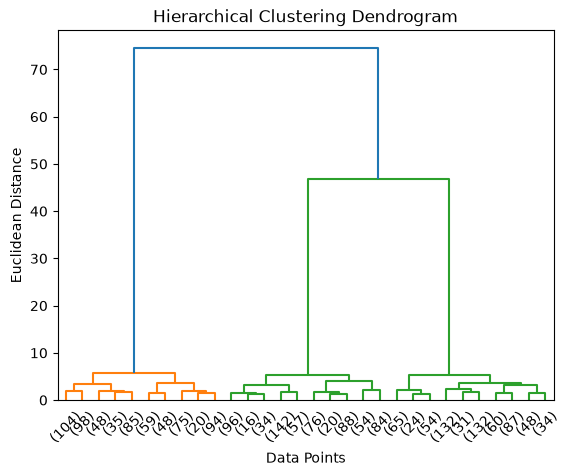

In [12]:
dendrogram(Z,truncate_mode="lastp",p=30)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()



In [14]:
start = time.perf_counter()

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_time = time.perf_counter() - start

In [18]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)

In [20]:
print("Hierarchical Clustering Time:",hierarchical_time, "seconds")

print("K-Means Execution Time:",kmeans_time, "seconds")

Hierarchical Clustering Time: 0.05735990000005131 seconds
K-Means Execution Time: 0.020498299999985647 seconds


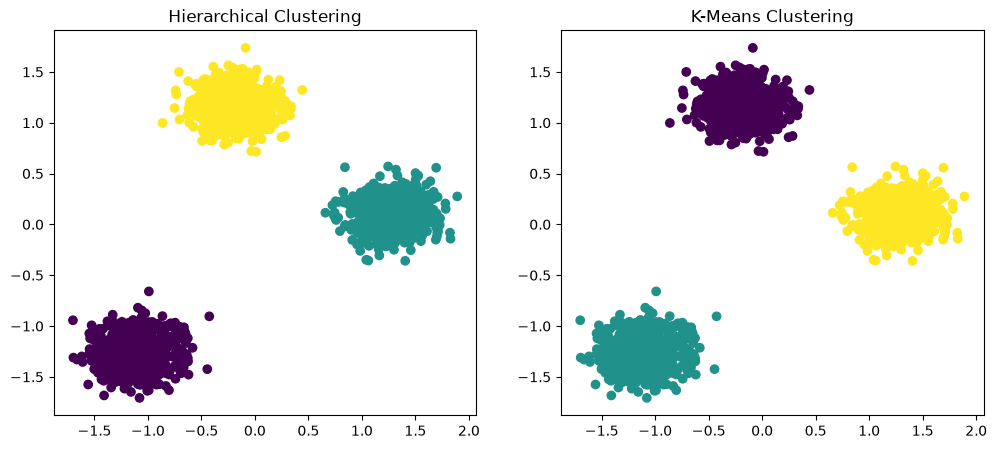

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=labels, cmap="viridis")
plt.title("Hierarchical Clustering")

plt.subplot(1, 2, 2)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=kmeans_labels, cmap="viridis")
plt.title("K-Means Clustering")

plt.show()